In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
df = pd.read_csv("../dataset/adult_cleaned.csv")

X = df.drop("income", axis=1)

y = (
    df["income"]
    .astype(str)
    .str.strip()
    .str.replace(".", "", regex=False)
    .eq(">50K")
    .astype(int)
)

print("Dataset loaded:", df.shape)

Dataset loaded: (45194, 15)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (36155, 14)
Testing: (9039, 14)


In [4]:
categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

def create_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_columns
            ),
            ("numerical", "passthrough", numerical_columns)
        ]
    )

baseline_model = Pipeline(
    steps=[
        ("preprocessing", create_preprocessor()),
        ("classifier", DecisionTreeClassifier(
            max_depth=8,
            random_state=42
        ))
    ]
)

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

print("Baseline model trained!")

C:\Users\Admin\AppData\Local\Temp\ipykernel_13008\3926130295.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(


Baseline model trained!


In [5]:
training_data = X_train.copy()
training_data["income"] = y_train.values

group_counts = training_data.groupby(
    ["sex", "income"]
).size()

gender_counts = training_data.groupby("sex").size()
income_counts = training_data.groupby("income").size()

total = len(training_data)

weights = {}

for gender in gender_counts.index:
    for income in income_counts.index:
        actual_count = group_counts.get((gender, income), 0)

        expected_count = (
            gender_counts[gender] * income_counts[income] / total
        )

        weights[(gender, income)] = (
            expected_count / actual_count
            if actual_count > 0 else 0
        )

sample_weights = [
    weights[(gender, income)]
    for gender, income in zip(X_train["sex"], y_train)
]

reweighted_model = Pipeline(
    steps=[
        ("preprocessing", create_preprocessor()),
        ("classifier", DecisionTreeClassifier(
            max_depth=8,
            random_state=42
        ))
    ]
)

reweighted_model.fit(
    X_train,
    y_train,
    classifier__sample_weight=sample_weights
)

reweighted_predictions = reweighted_model.predict(X_test)

print("Reweighted model trained!")

Reweighted model trained!


In [6]:
def calculate_performance(y_true, predictions):
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1 Score": f1_score(y_true, predictions, zero_division=0)
    }

performance_comparison = pd.DataFrame(
    {
        "Baseline": calculate_performance(
            y_test, baseline_predictions
        ),
        "Reweighted": calculate_performance(
            y_test, reweighted_predictions
        )
    }
)

print("PERFORMANCE COMPARISON")
display(performance_comparison.round(4))

PERFORMANCE COMPARISON


,Baseline,Reweighted
Accuracy,0.8491,0.8401
Precision,0.7739,0.7322
Recall,0.5529,0.5600
F1 Score,0.6450,0.6346


In [7]:
def calculate_fairness(predictions):
    results = pd.DataFrame({
        "sex": X_test["sex"].values,
        "actual": y_test.values,
        "predicted": predictions
    })

    group_results = results.groupby("sex").apply(
        lambda group: pd.Series({
            "Selection Rate": group["predicted"].mean(),
            "True Positive Rate": (
                group.loc[group["actual"] == 1, "predicted"].mean()
            )
        }),
        include_groups=False
    )

    dpd = (
        group_results["Selection Rate"].max()
        - group_results["Selection Rate"].min()
    )

    eod = (
        group_results["True Positive Rate"].max()
        - group_results["True Positive Rate"].min()
    )

    return group_results, dpd, eod


baseline_groups, baseline_dpd, baseline_eod = calculate_fairness(
    baseline_predictions
)

reweighted_groups, reweighted_dpd, reweighted_eod = calculate_fairness(
    reweighted_predictions
)

print("BASELINE FAIRNESS")
display(baseline_groups.round(4))

print("REWEIGHTED FAIRNESS")
display(reweighted_groups.round(4))

BASELINE FAIRNESS


,Selection Rate,True Positive Rate
sex,,
Female,0.0651,0.4307
Male,0.2310,0.5747


REWEIGHTED FAIRNESS


,Selection Rate,True Positive Rate
sex,,
Female,0.1441,0.6991
Male,0.2115,0.5352


In [8]:
fairness_comparison = pd.DataFrame({
    "Metric": [
        "Demographic Parity Difference",
        "Equal Opportunity Difference"
    ],
    "Baseline": [
        baseline_dpd,
        baseline_eod
    ],
    "Reweighted": [
        reweighted_dpd,
        reweighted_eod
    ]
})

display(fairness_comparison.round(4))

,Metric,Baseline,Reweighted
0,Demographic Parity Difference,0.1659,0.0674
1,Equal Opportunity Difference,0.1440,0.1639


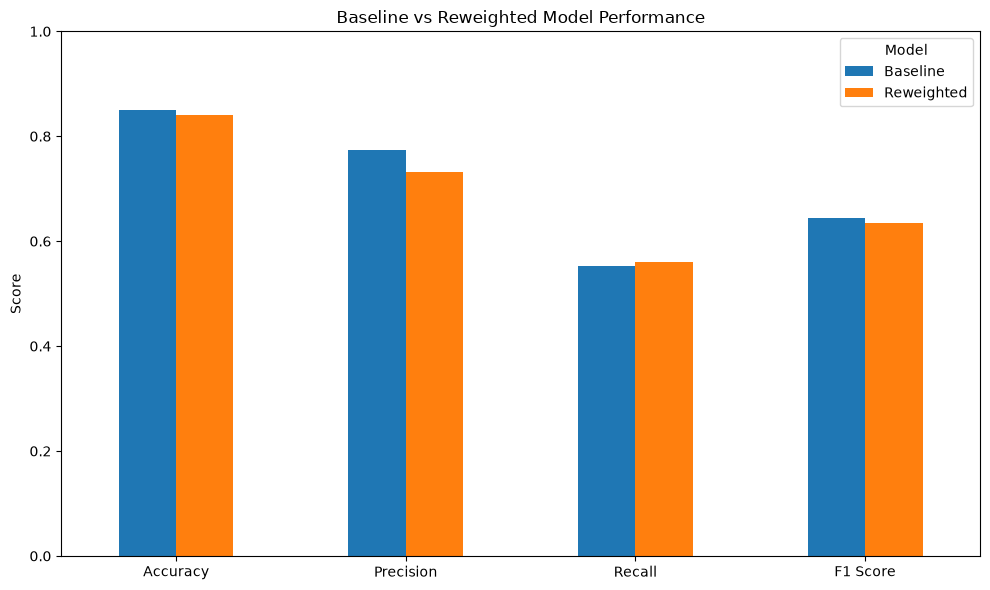

In [9]:
performance_comparison.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Baseline vs Reweighted Model Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

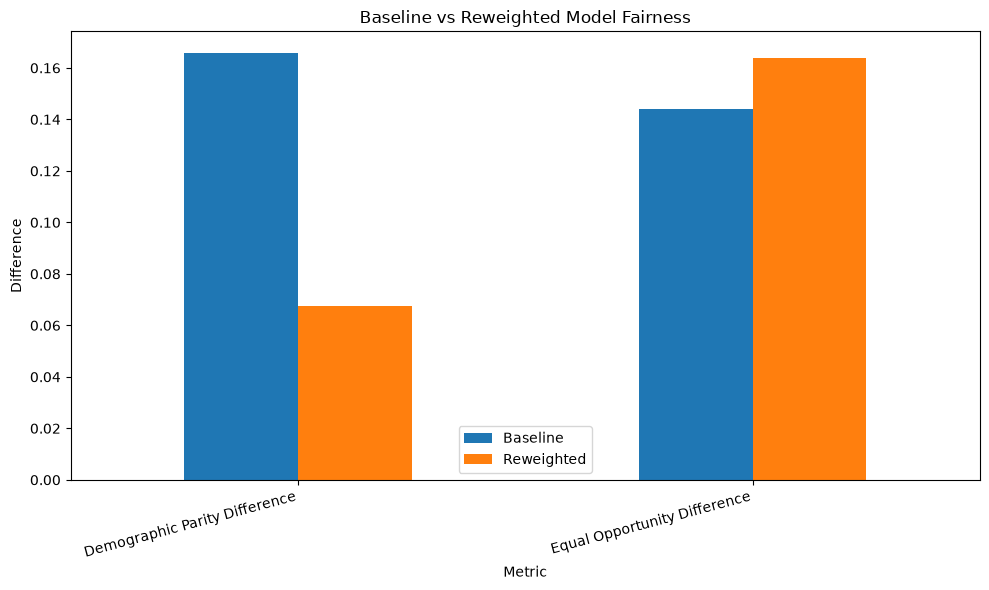

In [10]:
fairness_comparison.set_index("Metric").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Baseline vs Reweighted Model Fairness")
plt.ylabel("Difference")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

In [11]:
from pathlib import Path

results_path = Path("../results")
results_path.mkdir(exist_ok=True)

performance_comparison.to_csv(
    results_path / "performance_comparison.csv"
)

fairness_comparison.to_csv(
    results_path / "fairness_comparison.csv",
    index=False
)

print("Comparison results saved successfully!")

Comparison results saved successfully!
